###Câu a) Đọc bộ dữ liệu Iris

In [1]:
def in_thong_tin():
    print("Họ và tên: Nguyễn Gia Huy")
    print("Mã sinh viên: 6451071027")
    print("-" * 30)

in_thong_tin()

from sklearn.datasets import load_iris

iris = load_iris()
print(type(iris))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
<class 'sklearn.utils._bunch.Bunch'>


###Câu b) Khảo sát bộ dữ liệu

In [2]:
in_thong_tin()
import pandas as pd

print("Tên các thuộc tính:", iris.feature_names)
print("Tên các lớp       :", iris.target_names)

print("data.shape  :", iris.data.shape)
print("target.shape:", iris.target.shape)
print("Số mẫu:", iris.data.shape[0], "| Số thuộc tính:", iris.data.shape[1])

print("5 mẫu dữ liệu đầu tiên:\n", iris.data[:5])
print("5 nhãn đầu tiên:", iris.target[:5])

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target
print(df.describe())

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Tên các thuộc tính: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Tên các lớp       : ['setosa' 'versicolor' 'virginica']
data.shape  : (150, 4)
target.shape: (150,)
Số mẫu: 150 | Số thuộc tính: 4
5 mẫu dữ liệu đầu tiên:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
5 nhãn đầu tiên: [0 0 0 0 0]
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max           

###Câu c) Chuẩn hóa về [0,1]

In [3]:
in_thong_tin()
import numpy as np

X = iris.data
Y = iris.target

X_max = X.max(axis=0)      # giữ lại để dùng ở câu i
X = X / X_max

print("Max từng cột trước chuẩn hóa:", X_max)
print("Min/Max sau chuẩn hóa:", X.min(), X.max())
print(X[:5])

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Max từng cột trước chuẩn hóa: [7.9 4.4 6.9 2.5]
Min/Max sau chuẩn hóa: 0.04 1.0
[[0.64556962 0.79545455 0.20289855 0.08      ]
 [0.62025316 0.68181818 0.20289855 0.08      ]
 [0.59493671 0.72727273 0.1884058  0.08      ]
 [0.58227848 0.70454545 0.2173913  0.08      ]
 [0.63291139 0.81818182 0.20289855 0.08      ]]


###Câu d) Chia train/test 8:2

In [4]:
in_thong_tin()
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
X_train: (120, 4) | y_train: (120,)
X_test : (30, 4) | y_test : (30,)


###Câu e) Decision Tree

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
===== Decision Tree =====
Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



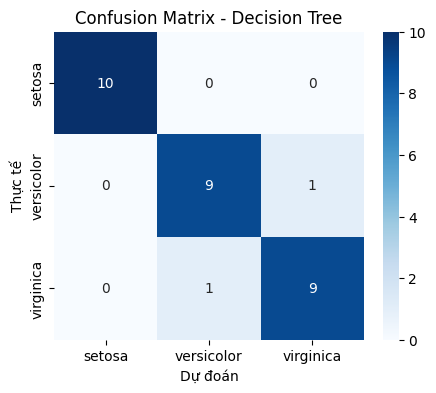

In [5]:
in_thong_tin()
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def danh_gia(ten_mo_hinh, y_true, y_pred):
    print(f"===== {ten_mo_hinh} =====")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print(classification_report(y_true, y_pred, target_names=iris.target_names))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    plt.xlabel('Dự đoán'); plt.ylabel('Thực tế')
    plt.title(f'Confusion Matrix - {ten_mo_hinh}')
    plt.show()

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

danh_gia("Decision Tree", y_test, y_pred_dt)

###Câu f) Naïve Bayes

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
===== Naive Bayes =====
Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



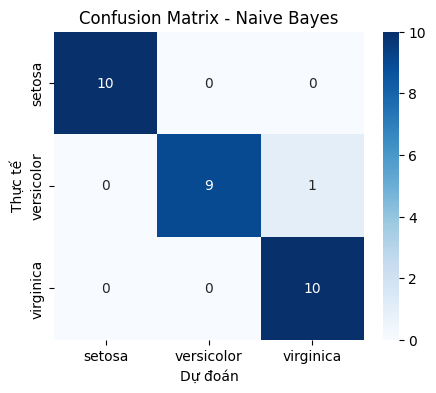

In [6]:
in_thong_tin()
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

danh_gia("Naive Bayes", y_test, y_pred_nb)

###Câu g) K Nearest Neighbors

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
===== KNN (k=5) =====
Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



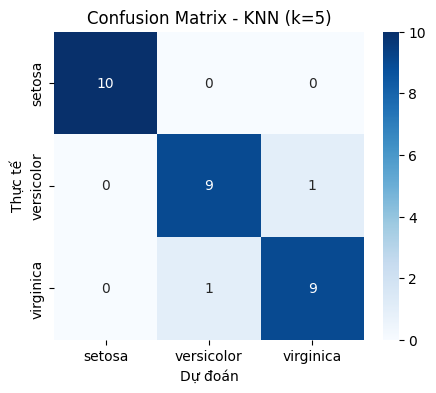

In [7]:
in_thong_tin()
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

danh_gia("KNN (k=5)", y_test, y_pred_knn)

###Câu h) Neural Network

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333 (1.30 KB)

 Trainable params: 333 (1.30 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5500 - loss: 1.0586
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6333 - loss: 0.9807
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6583 - loss: 0.8822
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7000 - loss: 0.7585
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7000 - loss: 0.6394
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6750 - loss: 0.5492
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8333 - loss: 0.4725
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9083 - loss: 0.4220
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9167 - loss: 0.3611
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9333 - loss: 0.3161
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9500 - loss: 0.2814
Epoch 12/100
120/120 ━━━━━━━━━━━━━━━━━━━━

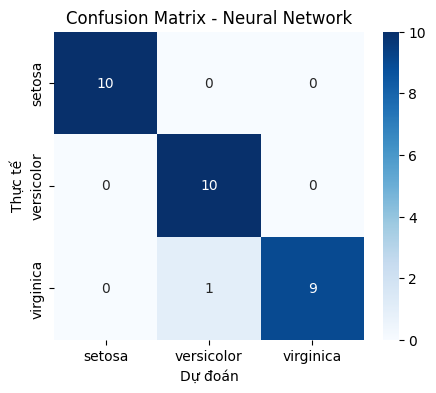

In [8]:
in_thong_tin()
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

nn = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(10, activation='relu'),
    Dense(20, activation='relu'),
    Dense(len(iris.target_names), activation='softmax')
])
nn.summary()

nn.compile(optimizer='adam',
           loss='sparse_categorical_crossentropy',
           metrics=['accuracy'])

history = nn.fit(X_train, y_train, epochs=100, batch_size=1, verbose=1)

y_prob_nn = nn.predict(X_test)
y_pred_nn = np.argmax(y_prob_nn, axis=1)

danh_gia("Neural Network", y_test, y_pred_nn)

###Câu i) Dự đoán 3 mẫu mới

In [9]:
in_thong_tin()

X_new = np.array([[6.2, 2.9, 4.3, 1.3],
                  [5.1, 3.5, 1.4, 0.2],
                  [7.3, 2.8, 6.4, 2.1]])
X_new_scaled = X_new / X_max     # chuẩn hóa giống tập train

names = iris.target_names
print("Decision Tree :", names[dt.predict(X_new_scaled)])
print("Naive Bayes   :", names[nb.predict(X_new_scaled)])
print("KNN           :", names[knn.predict(X_new_scaled)])
print("Neural Network:", names[np.argmax(nn.predict(X_new_scaled), axis=1)])

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Decision Tree : ['versicolor' 'setosa' 'virginica']
Naive Bayes   : ['versicolor' 'setosa' 'virginica']
KNN           : ['versicolor' 'setosa' 'virginica']
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
Neural Network: ['versicolor' 'setosa' 'virginica']
